# ¿Lee bien una IA multimodal los gráficos y tablas cuando cambia la presentación?
**Proyecto de investigación · Inteligencia Artificial · Tema 07: IA multimodal**

## A. Identificación

| Campo | Respuesta |
|---|---|
| Curso y grupo | Inteligencia Artificial · Grupo XX |
| Integrantes | Santiago Guevara · Januar Mena |
| Tema | 07 · IA multimodal |
| Título del estudio | Robustez de Gemini al leer gráficos de barras y tablas ante cambios de presentación |
| Fechas | Inicio: [__] · Exposición: [__] |
| Funciones | **Santiago:** diseño experimental, código, ejecución y análisis. **Januar:** revisión de fuentes, verificación de respuestas de referencia y clasificación de fallos. Cada semana revisamos el trabajo del otro (rotación de revisión). |

**Motivación** *(Januar)*: ✍️ *Pendiente: 3–4 líneas sobre por qué importa que una IA lea bien gráficos (informes, decisiones, accesibilidad) y su relación con el curso (percepción → representación del conocimiento).*

## B. Pregunta, hipótesis y alcance

- **Pregunta:** ¿Gemini lee correctamente un valor de un gráfico de barras o de una tabla, y mantiene esa lectura cuando solo cambia la presentación (no los datos)?
- **Hipótesis:** en la versión clara acertará ≥ 80 %, pero el acierto caerá **≥ 15 puntos** con eje truncado o con distractores visuales, sobre todo en gráficos de barras (las tablas dependen de OCR, que es más estable).
- **Qué la contradiría:** caídas < 5 puntos en todas las variantes (el modelo es robusto) o acierto < 50 % ya en la versión clara (el problema no es la presentación sino la lectura básica).
- **Objetivo general:** medir si la lectura visual del modelo depende de la presentación.
- **Objetivos específicos:** (1) medir el acierto por variante; (2) medir consistencia y estabilidad entre repeticiones; (3) clasificar los tipos de fallo.
- **Alcance:** 1 modelo (**Gemini 3.5 Flash-Lite** vía API gratuita), gráficos sintéticos con datos conocidos. **Fuera:** gráficos reales de internet, otros tipos de gráfico, comparación entre modelos.
- **Alternativa ante fallos de acceso (ocurrió):** Gemini 3.6 Flash solo permitía ≈ 10 consultas diarias en el plan gratuito; se usó Gemini 3.5 Flash-Lite, de la misma familia (ver E).

## C. Fuentes y marco conceptual

*(Januar: completar con 5 fuentes de [docs/fuentes_candidatas.md](docs/fuentes_candidatas.md); ≥ 3 académicas y ≥ 2 de 2025–2026.)*

**Estrategia de búsqueda:** Google Scholar y arXiv, consultas `chart question answering multimodal LLM`, `misleading visualizations MLLM`, `vision language model robustness charts`; 2021–2026; se priorizan artículos originales.

| ID | Referencia | Año | Tipo / revisión por pares | Aporte | Limitación |
|---|---|---|---|---|---|
| F1 | | | | | |
| F2 | | | | | |
| F3 | | | | | |
| F4 | | | | | |
| F5 | | | | | |

**Síntesis crítica** *(Januar)*: ✍️ *Pendiente.*

**Cómo funciona un modelo multimodal (en nuestras palabras):**

```
imagen ──► codificador visual (ViT) ──► "tokens visuales" ──► proyección ─┐
                                                                          ├──► modelo de lenguaje ──► "72"
pregunta (texto) ──────────────────────► tokens de texto ─────────────────┘
```
La imagen se corta en parches; un *Vision Transformer* convierte cada parche en un vector. Una capa de proyección pone esos vectores en el mismo "idioma" que las palabras (**alineación texto–imagen**, idea popularizada por CLIP), y el modelo de lenguaje genera la respuesta mirando ambos. El modelo **no mide píxeles con regla**: estima. Leer una tabla depende sobre todo de reconocer texto (**OCR**); leer una barra exige **razonamiento espacial** (comparar la altura con el eje). Por eso esperamos más fallos en barras.

- **Datos:** imágenes sintéticas con valores conocidos · **Modelo:** Gemini 3.5 Flash-Lite · **Herramientas:** matplotlib, API de Gemini · **Decisiones:** variantes, tolerancia ±3 · **Evaluación:** comparación automática con la referencia.

## D. Protocolo experimental

| Elemento | Decisión |
|---|---|
| Condición A (referencia) | Gráfico/tabla **clara** |
| Condición A (referencia) detalle | Barras: 7 categorías, eje 0–100 con marcas cada 20 y **sin cuadrícula**. Tablas: 8 filas × 4 columnas |
| Condición B (alternativas) | Mismos datos con: **escala** (barras: eje Y truncado; tablas: separador de miles y letra pequeña), **reordenada** (otro orden y colores), **distractor** (línea de meta, cuadro con otros números y flecha con % sobre la barra / columna Total y fila Promedio), **baja_resolucion** (≈ 56 % de los píxeles) |
| Control | **datos_cambiados**: el valor preguntado cambia (±12–20 en barras, ±300–900 en tablas) y la referencia se recalcula |
| Factor que cambia | Solo la presentación (un factor por variante) |
| Se mantiene | Pregunta, prompt, modelo, temperatura, datos |
| Casos | 20 familias finales (12 barras + 8 tablas) × 6 imágenes × 3 repeticiones = **360 consultas**; piloto separado de 6 familias |
| Exploración de estrés (separada) | 16 familias nuevas: pregunta de **proporción** ("¿cuántas veces es mayor A que B?", ±0,1) con eje desde 0 vs. truncado, y resolución **muy baja / extrema** (40 y 30 ppp) |
| Referencia | Generada por código (`data/referencias.csv`); Januar verificó a mano 10 imágenes |
| Métrica principal | Acierto = valor leído dentro de **±3** (barras, escala 0–100) o **exacto** (tablas), con denominador |
| Secundarias | Error absoluto medio, estabilidad entre repeticiones, consistencia por familia, dirección correcta en el control, tiempo |
| Repeticiones | 3 por imagen (temperatura 1.0, valor por defecto) |
| Modelo y fecha | `gemini-3.5-flash-lite` (API gratuita de Google AI Studio), versión registrada en `data/salidas.csv` · 2026-11-25 |
| Exclusión | Errores de conexión se reintentan; respuestas sin número cuentan como fallo |

**Procedimiento:** `python src/generar_dataset.py` → `python src/consultar_modelo.py --fase final --reps 3` → `python src/evaluar.py --fase final` (igual con `--fase estres`).

**Riesgos para la validez:** (1) las imágenes sintéticas son más limpias que las reales → no generalizamos a gráficos de internet; (2) la unidad independiente es la **familia** (20), no la consulta (300) → reportamos ambas y evitamos conclusiones finas; (3) el modelo puede cambiar de versión → guardamos todas las salidas.

## E. Piloto y bitácora

**Piloto (6 familias, 1 repetición, casos que no se reutilizan):**

| Versión | Modelo | Resultado | Decisión |
|---|---|---|---|
| v1 | Gemini 3.6 Flash | 8/8 correctas; error 503 (saturación) y **límite diario ≈ 10 consultas** | Inviable para 360 consultas → cambiar a Gemini 3.5 Flash-Lite |
| v1 | Gemini 3.5 Flash-Lite | **30/30 exactas** (incluso eje truncado y distractor) | **Efecto techo**: la prueba no discrimina. La cuadrícula densa servía de regla → protocolo v2 más exigente |
| v2 | Gemini 3.5 Flash-Lite | **36/36 exactas** | Se fija el protocolo; como no aparecen fallos, se añade una exploración de estrés separada |

Cambios v1 → v2: 7 barras (antes 5), sin cuadrícula y marcas cada 20; tablas de 8 × 4 (antes 5 × 3); flecha distractora sobre la barra preguntada; nueva variante de baja resolución. Evidencias en `data/piloto_v1/`. **Protocolo fijado el:** 2026-11-25, antes de la evaluación final.

**Correcciones posteriores (del código evaluador, no de los criterios):** (1) las respuestas numéricas se leían como enteros y no como texto, y todas quedaban como "sin número" → se corrigió la lectura; (2) |2 − 2,1| daba 0,1000000001 por redondeo binario y quedaba fuera de ±0,1 → se redondea el error a 6 decimales. Se volvió a puntuar todo con las mismas salidas guardadas; **no se repitió ninguna consulta**.
**Límite de uso:** el plan gratuito permitió ≈ 500 consultas diarias de Flash-Lite; la exploración de estrés se completó en dos días (el script retoma donde quedó).

| Semana | Integrante | Aporte verificable | Evidencia |
|---|---|---|---|
| 1 | Santiago | Repositorio, generador de imágenes, protocolo, pilotos v1 y v2 | commits en `src/`, `data/piloto_v1/` |
| 1 | Januar | Lectura de fuentes, tabla F1–F5 | PR `januar/fuentes` |
| 2 | Santiago | Script de consulta, piloto | `data/salidas.csv` |
| 2 | Januar | Verificación manual de 10 referencias | `docs/verificacion_referencias.md` |
| 3 | Santiago | Evaluación final, figura, análisis | `results/final/` |
| 3 | Januar | Clasificación de fallos | `data/etiquetas_fallos.csv` |

tipo
barras    12
tabla      8
Name: familias, dtype: int64


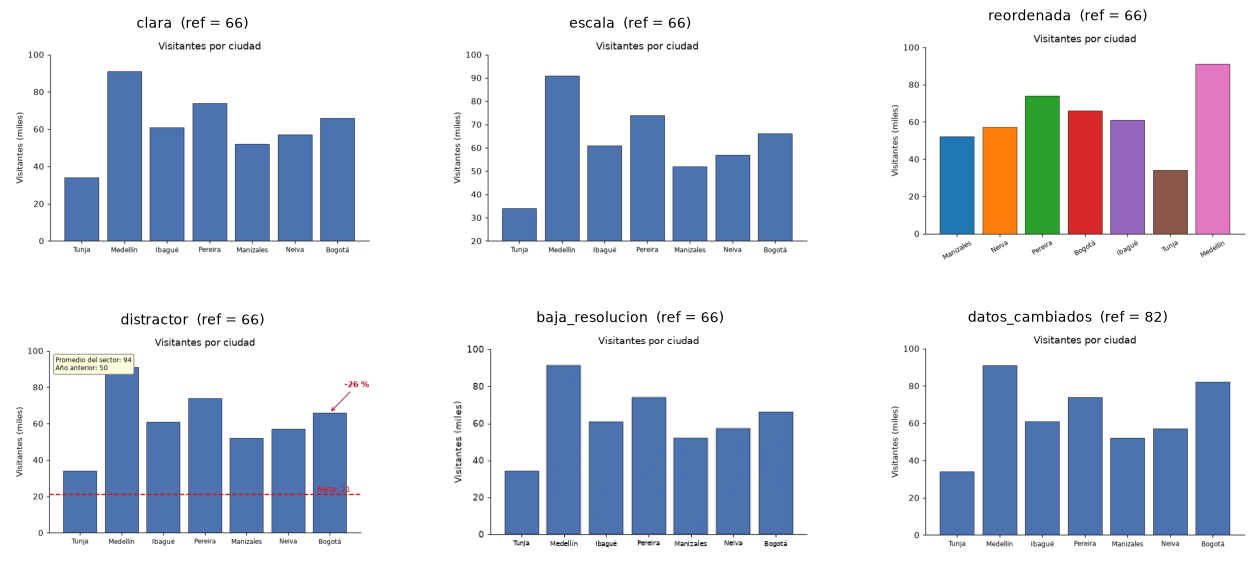

Pregunta: En el gráfico, ¿qué valor tiene la categoría «Bogotá»?


In [1]:
# Configuración y ejemplo de una familia (mismos datos, 5 presentaciones)
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

refs = pd.read_csv("data/referencias.csv")
print(refs[refs.fase == "final"].groupby("tipo").familia.nunique().rename("familias"))

ej = refs[(refs.fase == "final") & (refs.familia == "F02")]
fig, ejes = plt.subplots(2, 3, figsize=(16, 7))
ejes = ejes.ravel()
for ax, fila in zip(ejes, ej.itertuples()):
    ax.imshow(mpimg.imread(fila.archivo)); ax.axis("off")
    ax.set_title(f"{fila.variante}  (ref = {fila.respuesta_ref:g})", fontsize=10)
plt.show()
print("Pregunta:", ej.pregunta.iloc[0])

## F. Resultados

In [2]:
res_dir = Path("results/final")
if (res_dir / "resumen_variantes.csv").exists():
    res = pd.read_csv(res_dir / "resumen_variantes.csv")
    res["acierto"] = res.aciertos.astype(str) + "/" + res.n.astype(str) + " (" + res.pct_acierto.astype(str) + " %)"
    orden = ["clara", "escala", "reordenada", "distractor", "baja_resolucion", "datos_cambiados"]
    tabla = res.pivot(index="variante", columns="tipo", values="acierto").reindex(orden)
    display(tabla)
    display(res.pivot(index="variante", columns="tipo", values="error_abs_medio").reindex(orden).add_prefix("error medio · "))
    m = json.loads((res_dir / "resumen.json").read_text(encoding="utf-8"))
    for k in ["estabilidad_entre_repeticiones_pct", "consistencia_familia_pct", "control_direccion_correcta_pct",
              "tiempo_medio_s", "n_consultas", "modelo_version"]:
        print(f"{k}: {m.get(k)}")
else:
    print("Aún no hay resultados: ejecutar src/consultar_modelo.py y src/evaluar.py")

tipo,barras,tabla
variante,,
clara,36/36 (100.0 %),24/24 (100.0 %)
escala,36/36 (100.0 %),24/24 (100.0 %)
reordenada,36/36 (100.0 %),24/24 (100.0 %)
distractor,36/36 (100.0 %),24/24 (100.0 %)
baja_resolucion,36/36 (100.0 %),24/24 (100.0 %)
datos_cambiados,36/36 (100.0 %),24/24 (100.0 %)


tipo,error medio · barras,error medio · tabla
variante,,
clara,0.0,0.0
escala,0.0,0.0
reordenada,0.0,0.0
distractor,0.0,0.0
baja_resolucion,0.0,0.0
datos_cambiados,0.0,0.0


estabilidad_entre_repeticiones_pct: 100.0
consistencia_familia_pct: 100.0
control_direccion_correcta_pct: 100.0
tiempo_medio_s: 2.31
n_consultas: 360
modelo_version: ['gemini-3.5-flash-lite']


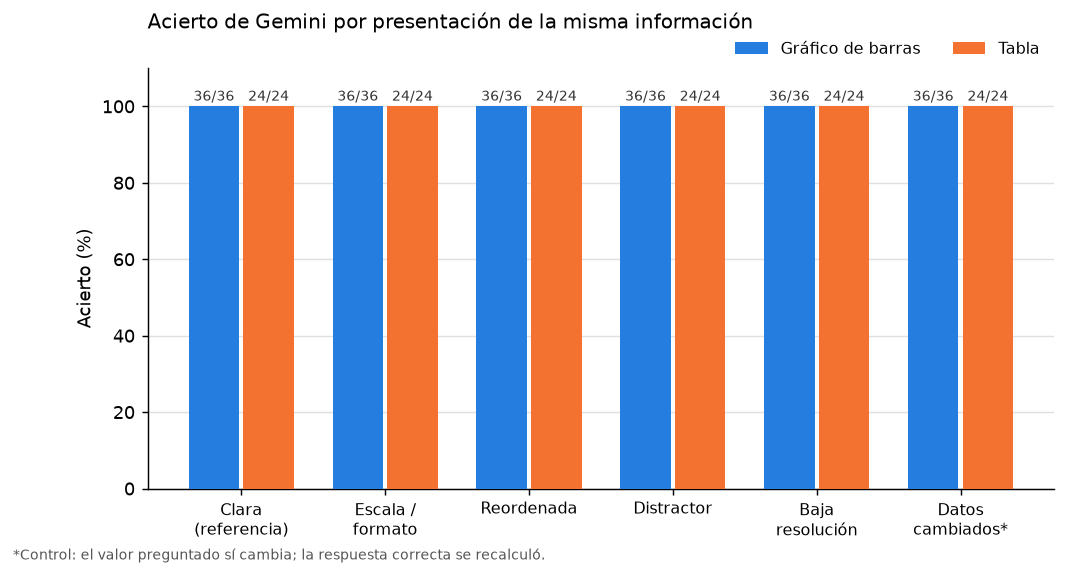

In [3]:
from IPython.display import Image
fig_path = res_dir / "acierto_por_variante.png"
Image(filename=str(fig_path)) if fig_path.exists() else print("Figura pendiente")

,tipo,variante,aciertos,n,pct_acierto,error_abs_medio
0,barras,proporcion_clara,11,11,100.0,0.02
1,barras,proporcion_truncada,10,11,90.9,3.54
2,barras,res_40,11,11,100.0,0.18
3,barras,res_30,10,10,100.0,0.40
4,tabla,res_40,6,6,100.0,0.00
5,tabla,res_30,2,6,33.3,871.67


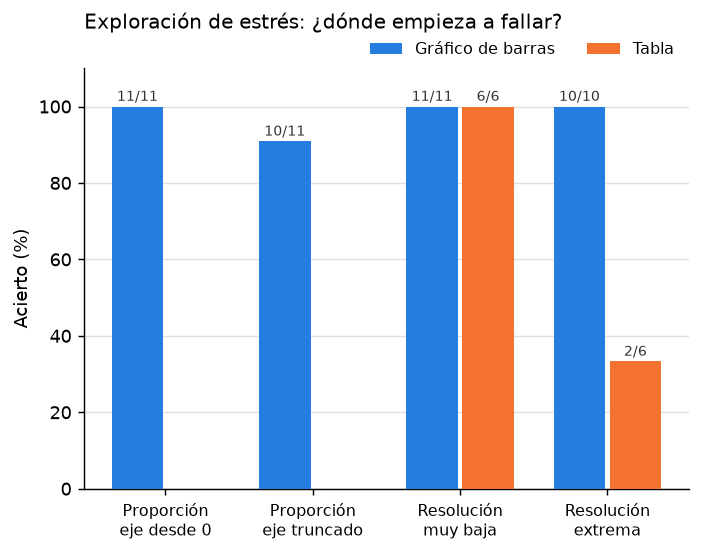

In [4]:
# Exploración de estrés (separada del estudio principal)
est = Path("results/estres")
if (est / "resumen_variantes.csv").exists():
    r = pd.read_csv(est / "resumen_variantes.csv")
    display(r[["tipo", "variante", "aciertos", "n", "pct_acierto", "error_abs_medio"]])
    display(Image(filename=str(est / "acierto_por_variante.png")))
else:
    print("Exploración de estrés pendiente")

**Interpretación:** en el estudio principal **todas las barras de la figura están al 100 %**: 216/216 lecturas de barras y 144/144 de tablas fueron **exactas** (error medio 0), en las 6 presentaciones y en las 3 repeticiones. Cambiar la presentación no movió el acierto ni un punto. El control (datos cambiados) también fue 100 %: el modelo sigue el cambio del dato, no repite una respuesta fija.

En la **exploración de estrés** sí aparecen fallos: las tablas a resolución extrema (30 ppp) caen con fuerza (errores de OCR en dígitos), las barras a 30 ppp siguen dentro de la tolerancia aunque con errores pequeños, y la pregunta de proporción con eje truncado se responde bien salvo cuando el modelo no respeta el formato.

## G. Análisis crítico

*(La evaluación principal no tuvo fallos; se analizan los de la exploración de estrés. Clasificación de Januar en `data/etiquetas_fallos_estres.csv`.)*

| Fallo | Evidencia | Causa posible | Cómo comprobarla | Mejora |
|---|---|---|---|---|
| 1. OCR a resolución extrema | Tablas a 30 ppp: 5165 → **3108**, 8077 → **6077**, 3832 → **3653** | Dígitos de ~4 px: el codificador visual confunde formas parecidas (8↔6, 5↔3) | Probar 35 y 50 ppp para hallar el umbral; contar qué dígitos se confunden | Exigir resolución mínima o pedir al modelo que diga "no legible" |
| 2. No respeta el formato | E06, proporción con eje truncado: escribe el razonamiento (84 / 67 ≈ **1,25**, correcto) pero la regla fijada toma el primer número (**40**, el inicio del eje) | Cuando la pregunta exige un cálculo, el modelo "explica" aunque se le pida solo el número | Contar respuestas con texto extra por tipo de pregunta | Pedir salida estructurada (JSON) y fijar antes la regla de extracción |
| 3. Degradación leve en barras | Barras a 30 ppp: p. ej. 84 → **85** (dentro de ±3) | Menos píxeles por unidad del eje → la estimación de altura pierde precisión | Error medio por resolución (0 → 0,2 → 0,4) | Tolerancia relativa a la resolución |

1. **¿Qué condición fue mejor?** Ninguna: las 6 presentaciones empataron en 100 %. Las diferencias solo aparecen bajo estrés, sobre todo en **tablas a 30 ppp**.
2. **¿La evidencia respalda la hipótesis?** **No: la contradice.** Predijimos una caída ≥ 15 puntos con eje truncado o distractores; la caída fue **0 puntos**, que cumple nuestro criterio de contradicción (< 5 puntos).
3. **¿Qué nos sorprendió?** Que lea **el valor exacto** de barras sin cuadrícula y con marcas cada 20, y que el eje truncado no lo engañe ni en proporciones: lee las etiquetas del eje y calcula (84 / 67), en vez de comparar alturas dibujadas.
4. **¿Coincide con la literatura?** Solo en parte. Tonglet et al. (2025) encontraron que los ejes truncados engañan a los MLLM; nosotros no lo observamos, posiblemente porque (a) usamos un modelo de 2026, más reciente; (b) nuestros gráficos son limpios y con el eje rotulado; (c) ellos usan gráficos reales y preguntas sobre la impresión visual. Sí coincide con ChartQAPro (2025): en gráficos simples los modelos rozan el 100 %, y por eso un benchmark simple sobreestima la capacidad real.
5. **Explicaciones alternativas:** el estilo por defecto de matplotlib es muy común en internet (el modelo pudo verlo mucho al entrenarse); con temperatura 1 las respuestas fueron idénticas (estabilidad 100 %), así que la aleatoriedad casi no influyó; Flash-Lite podría comportarse distinto de los modelos Flash completos.
6. **Hasta dónde generalizamos:** gráficos de barras y tablas **sintéticos**, un modelo, una fecha (2026-11-25). No podemos concluir nada sobre gráficos reales, de líneas o de dispersión, ni sobre otros modelos.
7. **Siguiente experimento:** usar gráficos reales engañosos (benchmark Misviz, 2025), preguntas de impresión visual ("¿la diferencia parece grande?"), barrer resoluciones entre 30 y 60 ppp y comparar con un modelo local pequeño.

**Conclusión:** en nuestras condiciones, Gemini 3.5 Flash-Lite leyó correctamente el **100 % de los valores (360/360)**, y su lectura **no cambió** con eje truncado, reordenamiento, distractores ni resolución reducida: **la presentación no afectó la lectura, y la hipótesis queda contradicha**. Los únicos fallos aparecen en condiciones extremas (texto de pocos píxeles) o cuando el modelo no respeta el formato pedido.

## H. Declaración de uso de IA y aportes

| Herramienta | Uso concreto | Parte afectada | Cómo lo verificamos |
|---|---|---|---|
| Claude (Anthropic), asistente de programación | Propuesta del diseño experimental, código en `src/`, borradores de redacción y del análisis | B, D, F, G, código | Ejecutamos y revisamos el código; comprobamos imágenes contra `referencias.csv`; revisamos cada fallo en su imagen; reescribimos y revisamos los textos |
| Gemini (Google) | **Objeto de estudio**, no fuente: sus respuestas son los datos del experimento | F, G | Registradas en `data/salidas.csv` con fecha y versión |

Las respuestas de los asistentes no se usan como referencias bibliográficas. Ambos integrantes entendemos y podemos explicar todo lo entregado.

**Reflexión individual** *(qué comprendí, qué hice, qué decisión defiendo, qué limitación veo)*:
- **Santiago:** ✍️
- **Januar:** ✍️

**Referencias:** *(Januar: formato APA, las 5 fuentes de la sección C.)*

## I. Exposición y verificación final

- **Hallazgo principal en una frase:** Gemini leyó bien el 100 % de los valores sin importar cómo se dibujara el gráfico; solo falla cuando los números son casi ilegibles.
- **Caso de demostración:** acierto: la proporción con eje truncado (E01: visualmente parece 5 veces, el modelo responde 2,07, correcto). Fallo: tabla a 30 ppp (E14: 8077 leído como 6077).
- **Intervenciones:** Januar: problema, fundamentos y conclusión · Santiago: método, resultados y demostración.

- [ ] Pregunta comprobable y 5 fuentes válidas
- [ ] Piloto separado de la evaluación final
- [ ] Tablas y figura coinciden con `data/salidas.csv`
- [ ] 3 fallos analizados y límites reconocidos
- [ ] Cuaderno ejecutado desde kernel limpio
- [ ] Uso de IA declarado y aportes registrados